Analyze time-series fluorescence data from PURE (Protein synthesis Using Recombinant Elements) experiments. 

## Setup 

In [2]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
# from cdk.analysis.cytosol import platereader as pr
import cdk.instruments.platereader.legacy as pr

# Set up plotting
pr.plot_setup()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load Data

In [2]:
# Specify file paths
data_file = "20260609-151420-cytation5-pure-timecourse-gfp-biotek-cdk.txt"
platemap_file = "20260609-3 DNA.csv"


# Load data
data, platemap = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek-cdk"  # Options: "cytation", "envision", "biotek-cdk"
)

# Checkout first few rows
data.head()

,Time,Temperature,Well,Data,Row,Column,Read,Plate,Clock Time,Reader,Name
0,0 days 00:00:10,37.00,A4,418,A,4,GFP-Gext,Plate 1,2026-06-09 15:47:07,Cytation5,0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0....
1,0 days 00:05:10,37.00,A4,416,A,4,GFP-Gext,Plate 1,2026-06-09 15:52:07,Cytation5,0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0....
2,0 days 00:10:10,37.00,A4,4484,A,4,GFP-Gext,Plate 1,2026-06-09 15:57:07,Cytation5,0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0....
3,0 days 00:15:10,37.00,A4,17522,A,4,GFP-Gext,Plate 1,2026-06-09 16:02:07,Cytation5,0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0....
4,0 days 00:20:10,37.00,A4,31544,A,4,GFP-Gext,Plate 1,2026-06-09 16:07:07,Cytation5,0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0....


## Plot Raw Curves

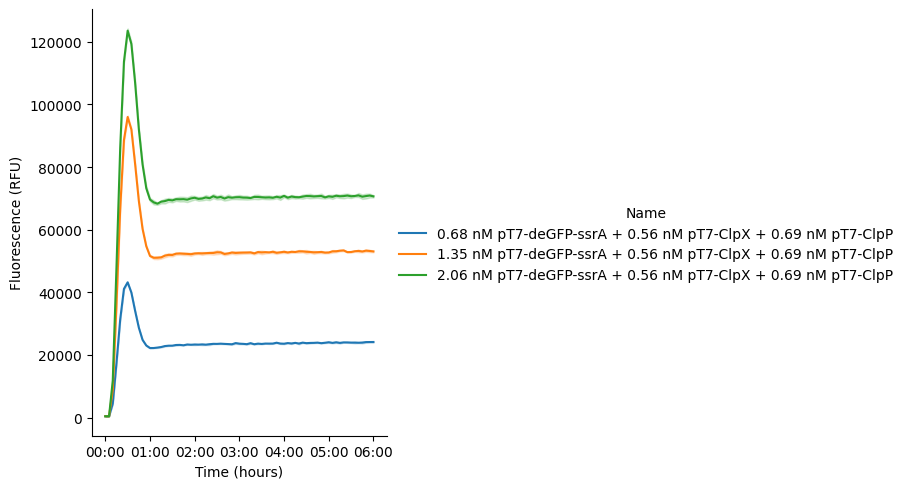

In [3]:
#| label: 20260609-3dna
g = pr.plot_curves(data=data)

## Normalize Data

In [4]:
data = pr.normalize_data_to_controls(data, ctrl_name = '10 uM HPTS')

Control name '10 uM HPTS' not found in data. No normalization applied.


Now replot your curves to see them normalized

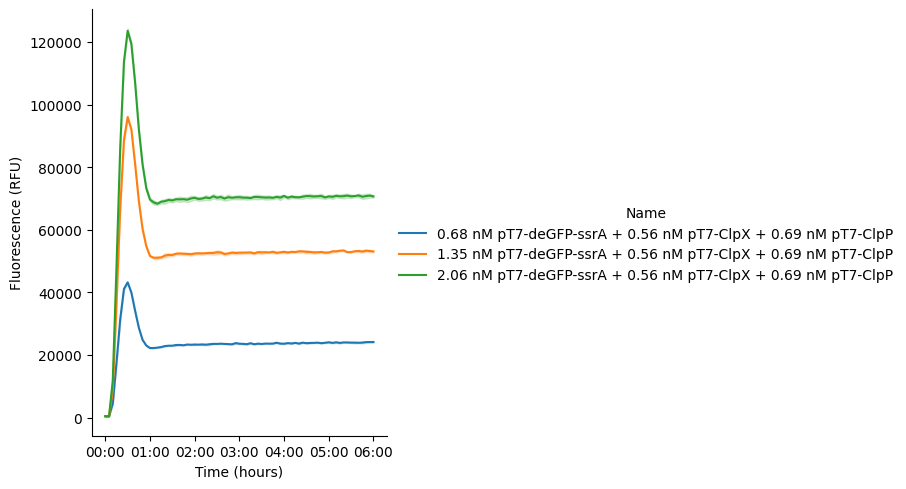

In [5]:
g = pr.plot_curves(data=data)

## Kinetic Analysis
**Metrics extracted:**

  - **Vmax** (`Velocity Max`): Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level and time to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit

In [6]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = pr.kinetic_analysis(
    data=data,
    group_by=['Well','Name'],  # Group by experimental condition
)

kinetics.head()

`Type` column not found in data. All data will be used for kinetic analysis.


Calculating Kinetics


/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


Velocity  \
                                                                             Time   
Well Name                                                                           
A4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 0 days 00:14:56.078172866   
A5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 0 days 00:15:03.882587759   
A6   2.06 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 0 days 00:00:16.681155854   
B4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 0 days 00:14:22.642011780   
B5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 0 days 00:15:04.589864629   

                                                                             \
                                                            Data        Max   
Well Name                                                                     
A4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 12768.23  827839.46   
A5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 29429.96 2538644.03   
A6   2.06 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 61286.22  358257.44   
B4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 13113.16  275180.30   
B5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 29702.48 1874911.21   

                                                                                Lag  \
                                                                               Time   
Well Name                                                                             
A4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...   0 days 00:14:00.553341570   
A5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...   0 days 00:14:22.148551870   
A6   2.06 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... -1 days +23:50:00.838003344   
B4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...   0 days 00:11:31.091323743   
B5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...   0 days 00:14:07.558398168   

                                                                   \
                                                             Data   
Well Name                                                           
A4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...   4679.60   
A5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...   9878.97   
A6   2.06 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... -62282.73   
B4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...   4165.94   
B5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...   9689.18   

                                                                     Steady State  \
                                                                             Time   
Well Name                                                                           
A4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 0 days 00:16:17.822910381   
A5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 0 days 00:16:05.324247656   
A6   2.06 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 0 days 00:15:23.337446245   
B4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 0 days 00:18:35.202277008   
B5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 0 days 00:16:28.552700143   

                                                                   \
                                                             Data   
Well Name                                                           
A4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...  24259.65   
A5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...  55916.93   
A6   2.06 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6... 116443.82   
B4   0.68 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...  24915.00   
B5   1.35 nM pT7-deGFP-ssrA + 0.56 nM pT7-ClpX + 0.6...  56434.72   

                                                                                                       Fit  \
                                                                                                    params   
Well Name                                              

## Visualize Fits on Individual Wells

`Type` column not found in data. All data will be used for kinetic analysis.


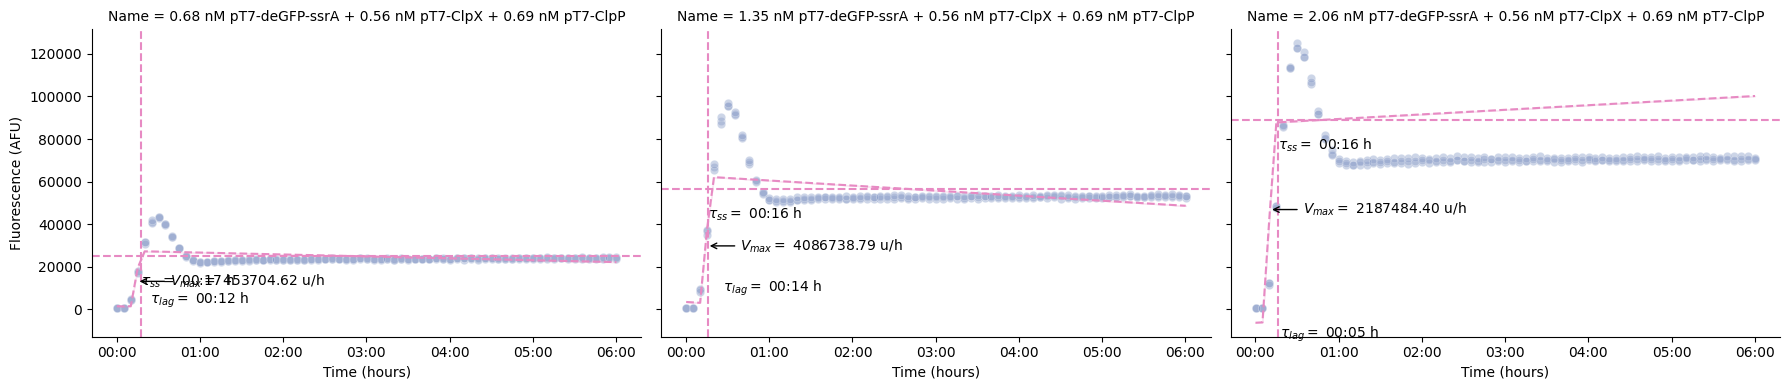

In [7]:
# Plot kinetic fits 
g = pr.plot_kinetics(data, kinetics=kinetics)

## Summary Plots

`Type` column not found in data. All data will be used for kinetic analysis.


Calculating Kinetics


/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


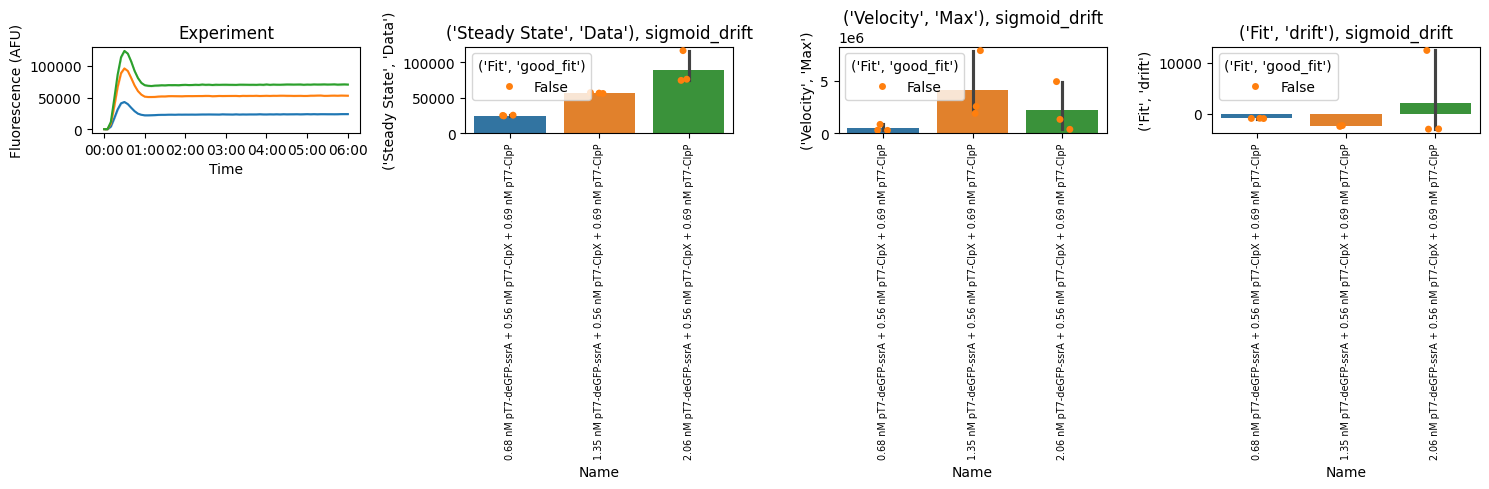

In [8]:
g = pr.plot_summary(data)
# g.savefig("summary.png", dpi=300)

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants